In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
# Load the dataset
data = pd.read_csv("data/student_habits_performance.csv")
print(f"Rows: {data.shape[0]}")
print(f"Columns: {data.shape[1]}")

Rows: 1000
Columns: 16


In [3]:
data.head()

,student_id,age,gender,study_hours_per_day,social_media_hours,netflix_hours,part_time_job,attendance_percentage,sleep_hours,diet_quality,exercise_frequency,parental_education_level,internet_quality,mental_health_rating,extracurricular_participation,exam_score
0,S1000,23,Female,0.0,1.2,1.1,No,85.0,8.0,Fair,6,Master,Average,8,Yes,56.2
1,S1001,20,Female,6.9,2.8,2.3,No,97.3,4.6,Good,6,High School,Average,8,No,100.0
2,S1002,21,Male,1.4,3.1,1.3,No,94.8,8.0,Poor,1,High School,Poor,1,No,34.3
3,S1003,23,Female,1.0,3.9,1.0,No,71.0,9.2,Poor,4,Master,Good,1,Yes,26.8
4,S1004,19,Female,5.0,4.4,0.5,No,90.9,4.9,Fair,3,Master,Good,1,No,66.4


In [4]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 16 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   student_id                     1000 non-null   object 
 1   age                            1000 non-null   int64  
 2   gender                         1000 non-null   object 
 3   study_hours_per_day            1000 non-null   float64
 4   social_media_hours             1000 non-null   float64
 5   netflix_hours                  1000 non-null   float64
 6   part_time_job                  1000 non-null   object 
 7   attendance_percentage          1000 non-null   float64
 8   sleep_hours                    1000 non-null   float64
 9   diet_quality                   1000 non-null   object 
 10  exercise_frequency             1000 non-null   int64  
 11  parental_education_level       909 non-null    object 
 12  internet_quality               1000 non-null   ob

In [5]:
missing_count = data.isnull().sum()
missing_percentage = (missing_count / len(data)) * 100

missing_df = pd.DataFrame({
    'Column': missing_count.index,
    'Missing Values': missing_count.values,
    'Percentage': missing_percentage.values
})

print(missing_df[missing_df['Missing Values'] > 0])

                      Column  Missing Values  Percentage
11  parental_education_level              91         9.1


In [6]:
data.describe()

,age,study_hours_per_day,social_media_hours,netflix_hours,attendance_percentage,sleep_hours,exercise_frequency,mental_health_rating,exam_score
count,1000.0000,1000.00000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000
mean,20.4980,3.55010,2.505500,1.819700,84.131700,6.470100,3.042000,5.438000,69.601500
std,2.3081,1.46889,1.172422,1.075118,9.399246,1.226377,2.025423,2.847501,16.888564
min,17.0000,0.00000,0.000000,0.000000,56.000000,3.200000,0.000000,1.000000,18.400000
25%,18.7500,2.60000,1.700000,1.000000,78.000000,5.600000,1.000000,3.000000,58.475000
50%,20.0000,3.50000,2.500000,1.800000,84.400000,6.500000,3.000000,5.000000,70.500000
75%,23.0000,4.50000,3.300000,2.525000,91.025000,7.300000,5.000000,8.000000,81.325000
max,24.0000,8.30000,7.200000,5.400000,100.000000,10.000000,6.000000,10.000000,100.000000


In [7]:
categorical_cols = data.select_dtypes(include=['object']).columns
for col in categorical_cols:
    print(f"\n{col}:")
    print(data[col].value_counts())
    print(f"Unique values: {data[col].nunique()}")


student_id:
student_id
S1000    1
S1001    1
S1002    1
S1003    1
S1004    1
        ..
S1995    1
S1996    1
S1997    1
S1998    1
S1999    1
Name: count, Length: 1000, dtype: int64
Unique values: 1000

gender:
gender
Female    481
Male      477
Other      42
Name: count, dtype: int64
Unique values: 3

part_time_job:
part_time_job
No     785
Yes    215
Name: count, dtype: int64
Unique values: 2

diet_quality:
diet_quality
Fair    437
Good    378
Poor    185
Name: count, dtype: int64
Unique values: 3

parental_education_level:
parental_education_level
High School    392
Bachelor       350
Master         167
Name: count, dtype: int64
Unique values: 3

internet_quality:
internet_quality
Good       447
Average    391
Poor       162
Name: count, dtype: int64
Unique values: 3

extracurricular_participation:
extracurricular_participation
No     682
Yes    318
Name: count, dtype: int64
Unique values: 2


In [8]:
print(f"Shape before cleaning: {data.shape}")

# Drop rows with missing values
data_clean = data.dropna()

print(f"Shape after dropping nulls: {data_clean.shape}")
print(f"Rows removed: {data.shape[0] - data_clean.shape[0]}")

duplicates = data_clean.duplicated().sum()
print(f"Duplicate rows found: {duplicates}")

Shape before cleaning: (1000, 16)
Shape after dropping nulls: (909, 16)
Rows removed: 91
Duplicate rows found: 0


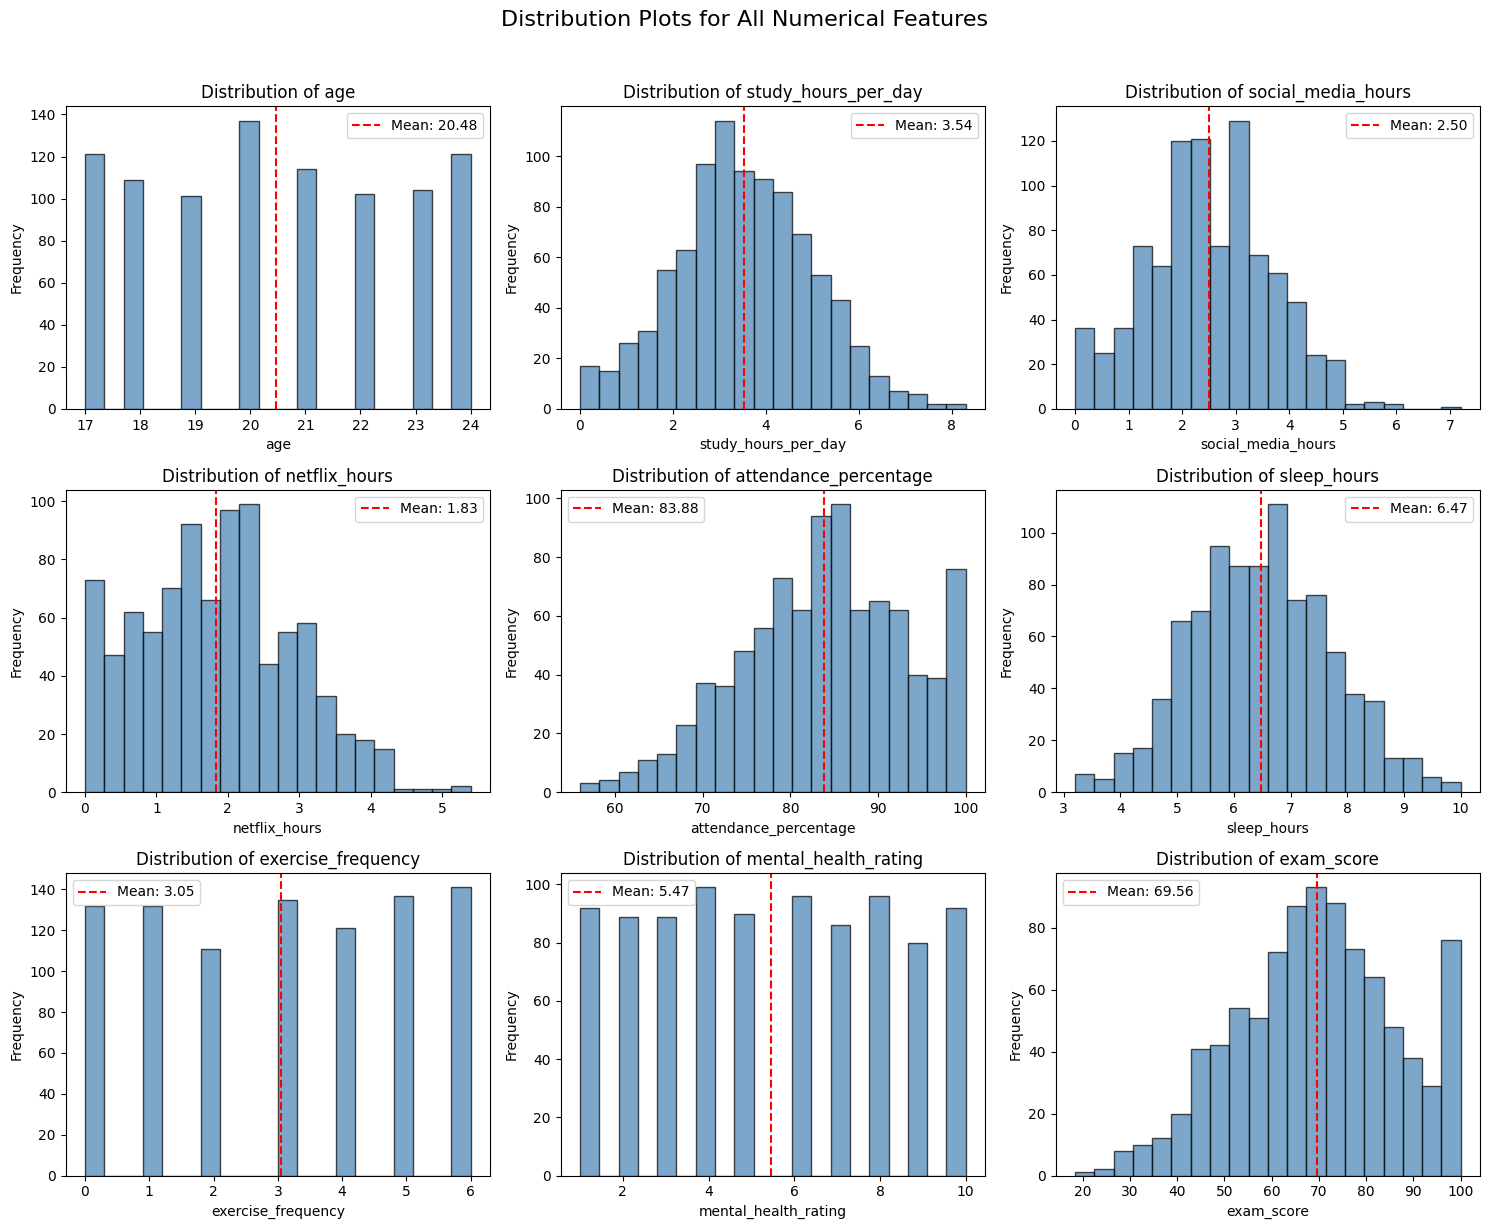

In [9]:
numerical_cols = ['age', 'study_hours_per_day', 'social_media_hours', 
                  'netflix_hours', 'attendance_percentage', 'sleep_hours',
                  'exercise_frequency', 'mental_health_rating', 'exam_score']

fig, axes = plt.subplots(3, 3, figsize=(15, 12))
axes = axes.ravel()

for i, col in enumerate(numerical_cols):
    axes[i].hist(data_clean[col], bins=20, edgecolor='black', alpha=0.7, color='steelblue')
    axes[i].set_title(f'Distribution of {col}', fontsize=12)
    axes[i].set_xlabel(col)
    axes[i].set_ylabel('Frequency')
    axes[i].axvline(data_clean[col].mean(), color='red', linestyle='--', label=f'Mean: {data_clean[col].mean():.2f}')
    axes[i].legend()

plt.suptitle('Distribution Plots for All Numerical Features', fontsize=16, y=1.02)
plt.tight_layout()
plt.show()

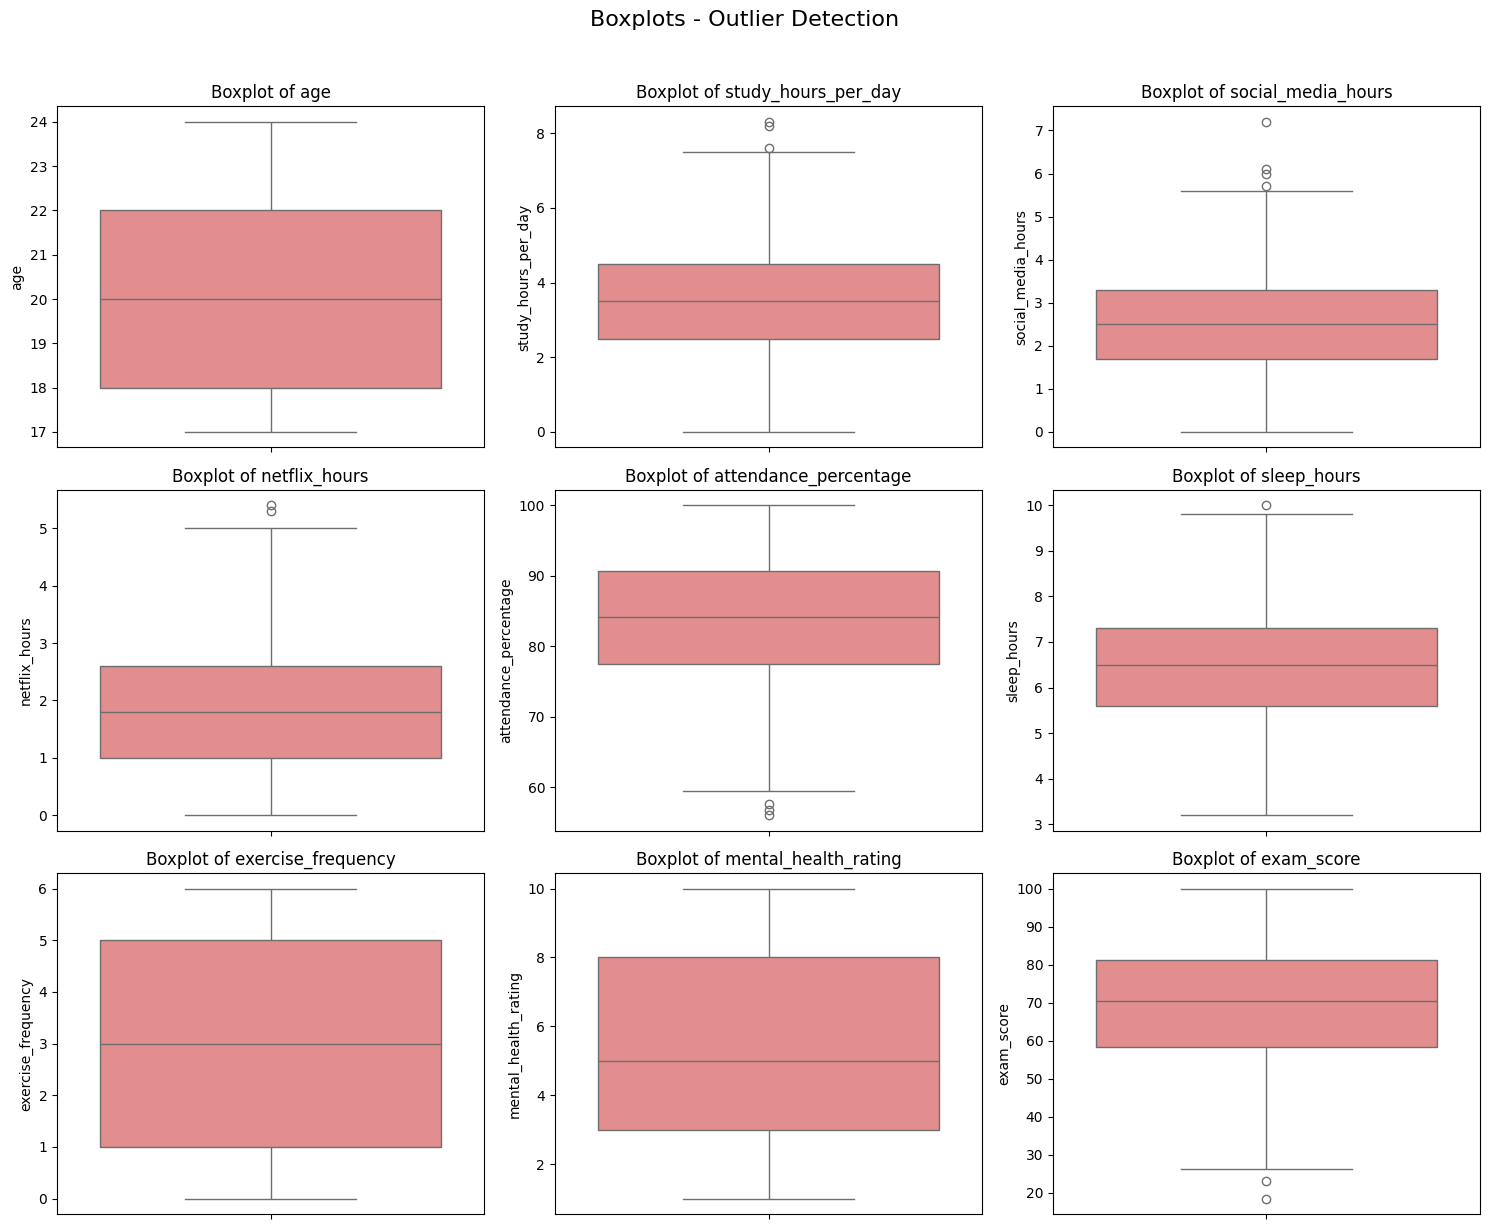

In [10]:
# Boxplots to check for outliers
fig, axes = plt.subplots(3, 3, figsize=(15, 12))
axes = axes.ravel()

for i, col in enumerate(numerical_cols):
    sns.boxplot(y=data_clean[col], ax=axes[i], color='lightcoral')
    axes[i].set_title(f'Boxplot of {col}', fontsize=12)

plt.suptitle('Boxplots - Outlier Detection', fontsize=16, y=1.02)
plt.tight_layout()
plt.show()

In [11]:
# 6. BIVARIATE ANALYSIS (Relationships)

# Calculate correlation matrix
correlation_matrix = data_clean[numerical_cols].corr()

# Display correlation with exam_score
print("\nCorrelation with Exam Score (sorted):")
corr_with_score = correlation_matrix['exam_score'].sort_values(ascending=False)
print(corr_with_score)


Correlation with Exam Score (sorted):
exam_score               1.000000
study_hours_per_day      0.822950
mental_health_rating     0.317945
exercise_frequency       0.161397
sleep_hours              0.122294
attendance_percentage    0.096005
age                     -0.012833
netflix_hours           -0.166578
social_media_hours      -0.171672
Name: exam_score, dtype: float64


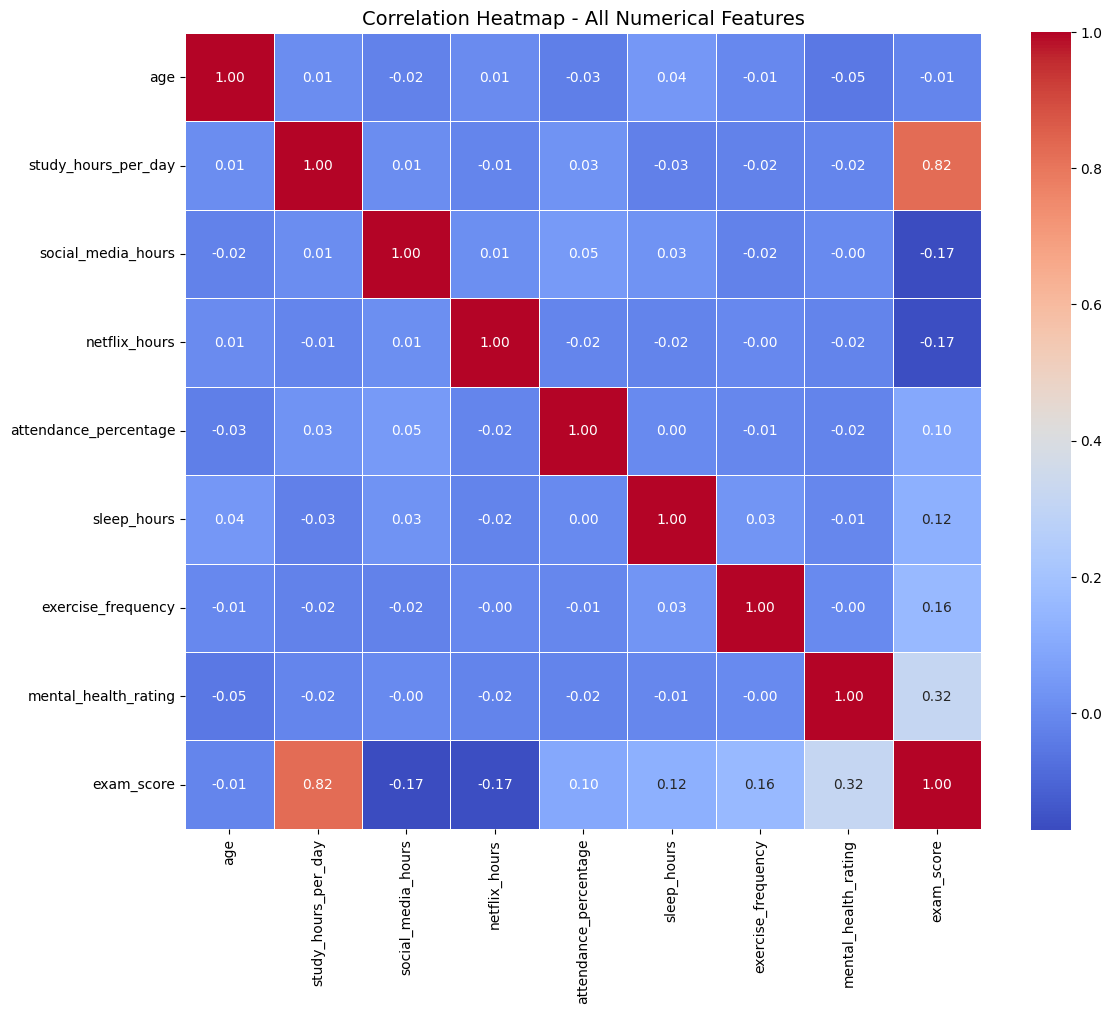

In [12]:
# Heatmap of correlations
plt.figure(figsize=(12, 10))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt='.2f', 
            linewidths=0.5, square=True)
plt.title('Correlation Heatmap - All Numerical Features', fontsize=14)
plt.tight_layout()
plt.show()

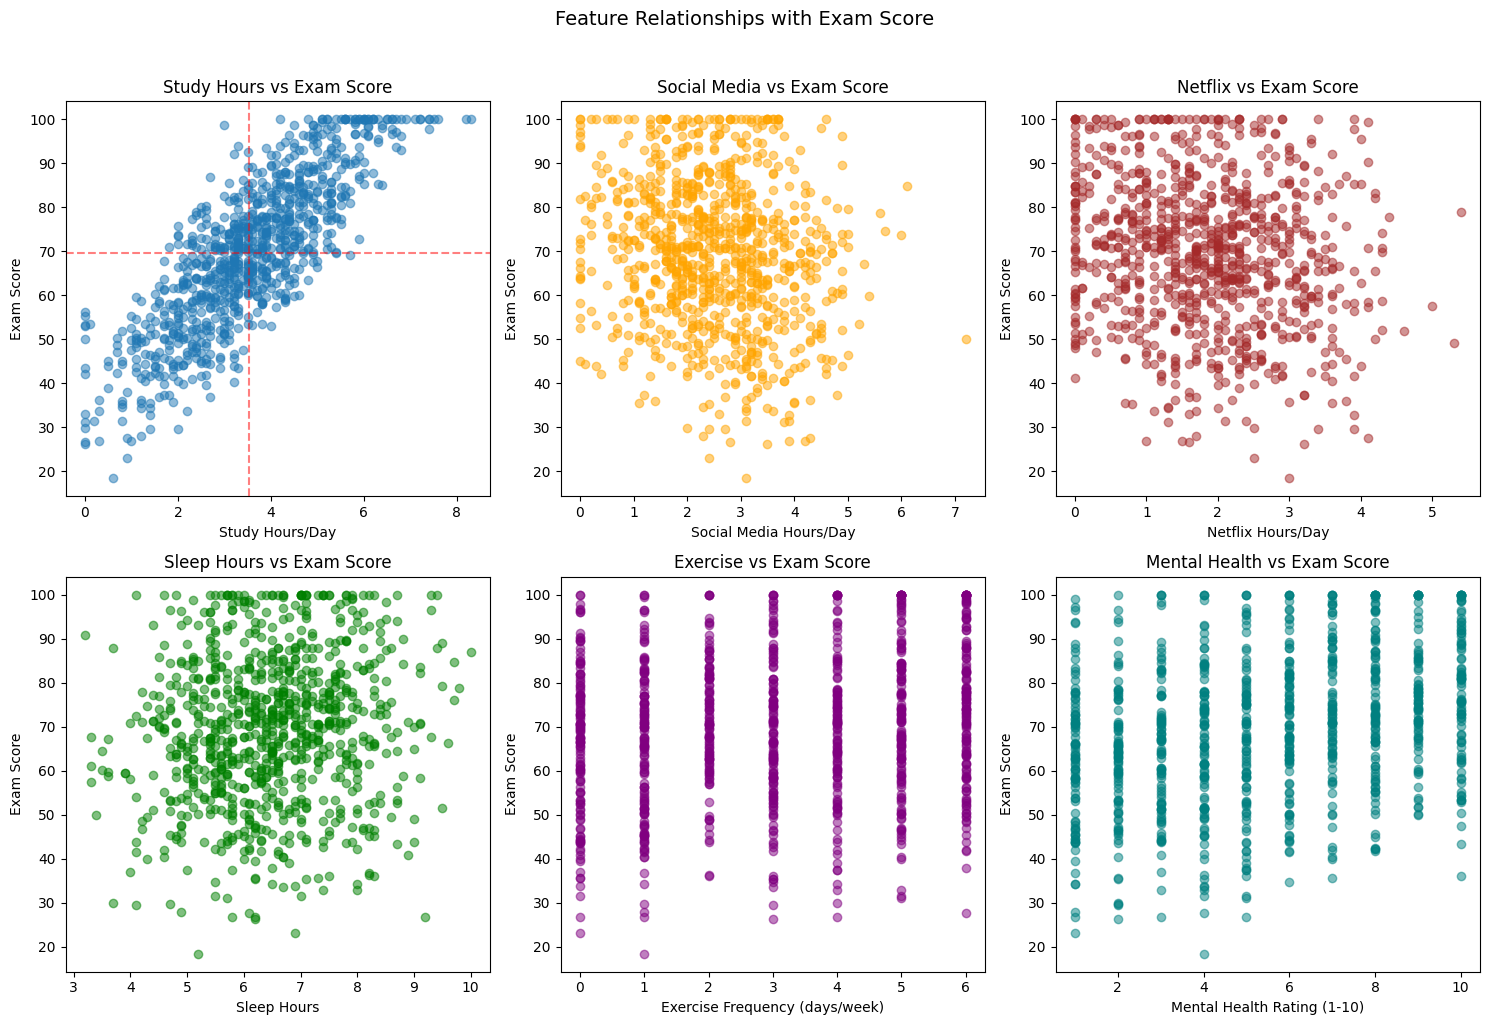

In [13]:
fig, axes = plt.subplots(2, 3, figsize=(15, 10))
axes = axes.ravel()

# Study hours vs Score
axes[0].scatter(data_clean['study_hours_per_day'], data_clean['exam_score'], alpha=0.5)
axes[0].set_xlabel('Study Hours/Day')
axes[0].set_ylabel('Exam Score')
axes[0].set_title('Study Hours vs Exam Score')
axes[0].axhline(y=data_clean['exam_score'].mean(), color='red', linestyle='--', alpha=0.5)
axes[0].axvline(x=data_clean['study_hours_per_day'].mean(), color='red', linestyle='--', alpha=0.5)

# Social media vs Score
axes[1].scatter(data_clean['social_media_hours'], data_clean['exam_score'], alpha=0.5, color='orange')
axes[1].set_xlabel('Social Media Hours/Day')
axes[1].set_ylabel('Exam Score')
axes[1].set_title('Social Media vs Exam Score')

# Netflix vs Score
axes[2].scatter(data_clean['netflix_hours'], data_clean['exam_score'], alpha=0.5, color='brown')
axes[2].set_xlabel('Netflix Hours/Day')
axes[2].set_ylabel('Exam Score')
axes[2].set_title('Netflix vs Exam Score')

# Sleep vs Score
axes[3].scatter(data_clean['sleep_hours'], data_clean['exam_score'], alpha=0.5, color='green')
axes[3].set_xlabel('Sleep Hours')
axes[3].set_ylabel('Exam Score')
axes[3].set_title('Sleep Hours vs Exam Score')

# Exercise vs Score
axes[4].scatter(data_clean['exercise_frequency'], data_clean['exam_score'], alpha=0.5, color='purple')
axes[4].set_xlabel('Exercise Frequency (days/week)')
axes[4].set_ylabel('Exam Score')
axes[4].set_title('Exercise vs Exam Score')

# Mental Health vs Score
axes[5].scatter(data_clean['mental_health_rating'], data_clean['exam_score'], alpha=0.5, color='teal')
axes[5].set_xlabel('Mental Health Rating (1-10)')
axes[5].set_ylabel('Exam Score')
axes[5].set_title('Mental Health vs Exam Score')

plt.suptitle('Feature Relationships with Exam Score', fontsize=14, y=1.02)
plt.tight_layout()
plt.show()

In [14]:

data_clean.to_csv("data/student_data_cleaned.csv", index=False)
print("\nCleaned data saved to ../data/student_data_cleaned.csv")


Cleaned data saved to ../data/student_data_cleaned.csv
